In [1]:
import importlib, common; importlib.reload(common)
from common import *
u = joblib.load(RES / "unsup.pkl")
for d in ("PRED", "SCORE", "BEST"): u[d].pop("Ensemble", None)
_, params, q = u["BEST"]["CANARI"]
span = cv_smooth(params, q); print("chosen span:", span)

a, b = next(GroupShuffleSplit(1, test_size=0.2, random_state=42).split(norm, groups=norm["unit"]))
Nf, Nc = norm.iloc[a], norm.iloc[b]
fn = f_canari(Nf[feats].values, **params)
sc = smooth(np.log(fn(Nc[feats].values)), Nc, span)
st = smooth(np.log(fn(test[feats].values)), test, span)
t1, t2 = np.quantile(sc, q)
u["PRED"]["CANARI+Smooth"], u["SCORE"]["CANARI+Smooth"] = zones(st, t1, t2), st
u["BEST"]["CANARI+Smooth"] = (None, dict(params, span=span), q)
joblib.dump(u, RES / "unsup.pkl")
print(list(u["PRED"]))

chosen span: 5
['Mahalanobis (d=1)', 'CANARI', 'Isolation Forest', 'One-Class SVM', 'LOF', 'Autoencoder', 'Hebbian (Sanger)', 'CANARI+Smooth']


In [2]:
from common import *
u, s = joblib.load(RES / "unsup.pkl"), joblib.load(RES / "sup.pkl")
PRED, SCORE = {**u["PRED"], **s["PRED"]}, {**u["SCORE"], **s["SCORE"]}
R = pd.DataFrame([metrics(n, yte, PRED[n], SCORE[n]) for n in PRED]).set_index("model").round(3).sort_values("macroF1", ascending=False)
print(R); R.to_csv(RES / "results.csv")

                         macroF1  near_P  near_R  near_F1    FAR  PR_AUC  \
model                                                                      
MLP                        0.839   0.754   0.721    0.737  0.044   0.845   
Random Forest              0.836   0.702   0.763    0.731  0.071   0.810   
Gradient Boosting          0.826   0.648   0.782    0.709  0.104   0.787   
Logistic Regression        0.786   0.586   0.737    0.653  0.130   0.704   
One-Class SVM              0.716   0.572   0.615    0.593  0.078   0.746   
CANARI                     0.651   0.534   0.576    0.554  0.074   0.713   
CANARI+Smooth              0.645   0.544   0.604    0.573  0.070   0.723   
Mahalanobis (d=1)          0.645   0.508   0.426    0.464  0.082   0.568   
Isolation Forest           0.619   0.552   0.636    0.591  0.065   0.744   
LOF                        0.599   0.463   0.509    0.485  0.089   0.627   
Hebbian (Sanger)           0.559   0.335   0.364    0.348  0.167   0.488   
Autoencoder 

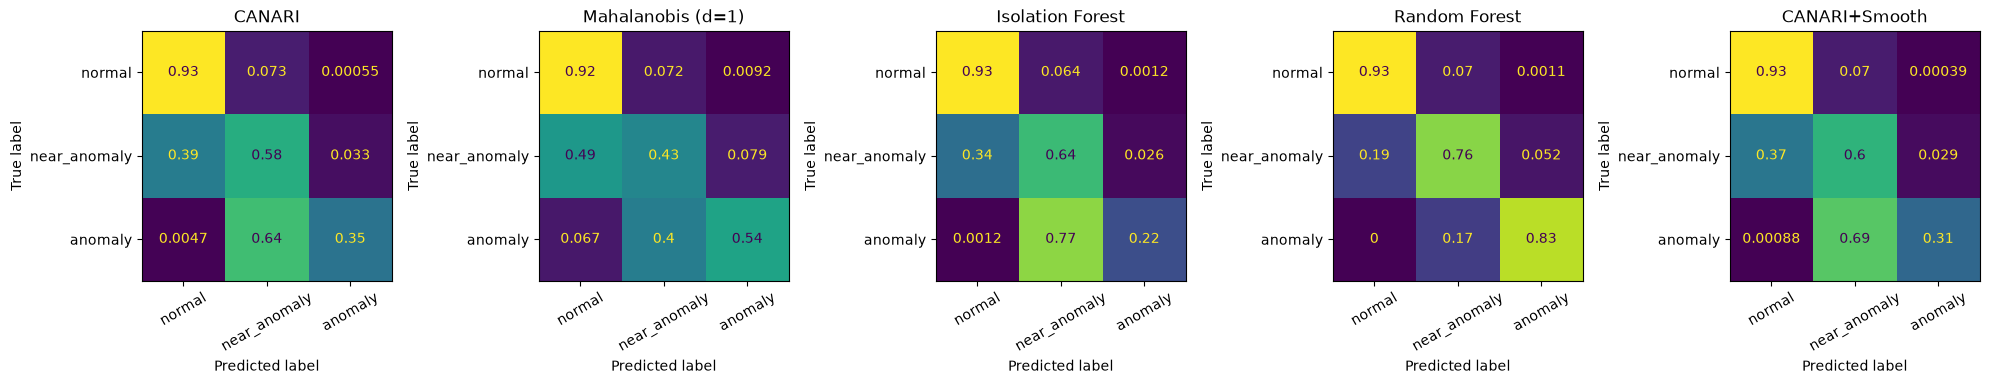

In [3]:
show = ["CANARI", "Mahalanobis (d=1)", "Isolation Forest", "Random Forest", "CANARI+Smooth"]
fig, ax = plt.subplots(1, 5, figsize=(20, 4))
for a, n in zip(ax, show):
    ConfusionMatrixDisplay.from_predictions(yte, PRED[n], labels=["normal", "near_anomaly", "anomaly"],
                                            normalize="true", ax=a, colorbar=False, xticks_rotation=30)
    a.set_title(n)
plt.tight_layout(); plt.show()

In [4]:
def lead(pred, k=3):    # RUL at the first point where k consecutive cycles are flagged (bigger = earlier)
    df = test[["unit", "cycle", "rul"]].assign(f=(pred != "normal")).sort_values(["unit", "cycle"])
    out = []
    for _, g in df.groupby("unit"):
        run = g.f.rolling(k).sum().values == k
        out.append(g.rul.values[np.argmax(run)] if run.any() else np.nan)
    s = pd.Series(out)
    return dict(median_lead_cycles=s.median(), missed_engines=s.isna().mean())

print(pd.DataFrame({n: lead(PRED[n]) for n in PRED}).T.round(2))

                         median_lead_cycles  missed_engines
Mahalanobis (d=1)                     182.0            0.03
CANARI                                 52.0            0.00
Isolation Forest                       46.0            0.00
One-Class SVM                          47.0            0.00
LOF                                    41.0            0.00
Autoencoder                           134.0            0.14
Hebbian (Sanger)                       71.0            0.03
CANARI+Smooth                         148.0            0.00
Majority/Random (floor)               167.5            0.06
Logistic Regression                    66.0            0.00
Random Forest                          56.0            0.00
Gradient Boosting                      62.0            0.00
MLP                                    49.0            0.00


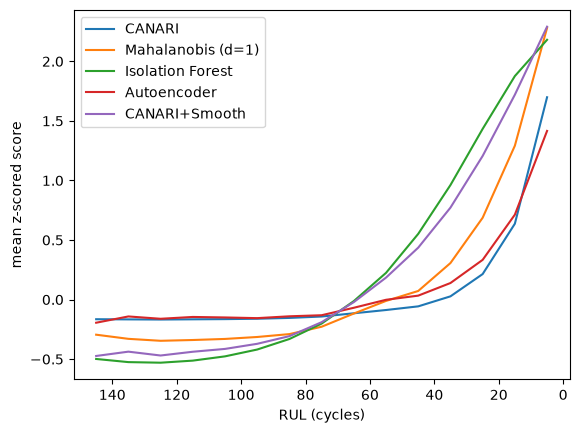

In [ ]:
import matplotlib.pyplot as plt
show = ["CANARI", "CANARI-growth", "CANARI-paper", "One-Class SVM", "Mahalanobis (d=1)"]
bins = np.arange(0, 160, 10)
b = pd.cut(test["rul"], bins)
for m in show:
    s = np.asarray(SCORE[m]); z = (s - s.mean()) / s.std()
    plt.plot(bins[:-1] + 5, pd.Series(z).groupby(b.values, observed=True).mean().values, label=m)
plt.gca().invert_xaxis(); plt.xlabel("RUL (cycles)"); plt.ylabel("mean z-scored score"); plt.legend(); plt.show()

In [6]:
print(pd.DataFrame({n: {k: f1_score(yte[test.subset == k], PRED[n][test.subset == k], average="macro")
      for k in sorted(test.subset.unique())} for n in ["CANARI", "Isolation Forest", "Random Forest", "CANARI+Smooth"]}).round(3))

       CANARI  Isolation Forest  Random Forest  CANARI+Smooth
FD001   0.662             0.512          0.846          0.658
FD002   0.623             0.528          0.837          0.624
FD003   0.674             0.707          0.838          0.661
FD004   0.662             0.680          0.829          0.649


In [7]:
def relabel(rul, A, B): return np.where(rul > A, "normal", np.where(rul > B, "near_anomaly", "anomaly"))
rows = []
for A in (40, 60, 80):
    for B in (10, 15, 25):
        y2 = relabel(test["rul"].values, A, B)
        rows.append(dict(A=A, B=B, **{n: round(f1_score(y2, PRED[n], average="macro"), 3)
                                      for n in ["CANARI", "Isolation Forest", "Random Forest", "CANARI+Smooth"]}))
print(pd.DataFrame(rows))

    A   B  CANARI  Isolation Forest  Random Forest  CANARI+Smooth
0  40  10   0.668             0.626          0.765          0.663
1  40  15   0.637             0.601          0.778          0.630
2  40  25   0.549             0.521          0.691          0.540
3  60  10   0.677             0.639          0.819          0.673
4  60  15   0.651             0.619          0.836          0.645
5  60  25   0.580             0.556          0.766          0.572
6  80  10   0.645             0.609          0.805          0.639
7  80  15   0.621             0.592          0.822          0.614
8  80  25   0.557             0.535          0.759          0.548


In [ ]:
old = ROOT / "run_20261029_201358_328692"      # v1 run folder
cols = ["macroF1", "near_F1", "FAR"]
a = pd.read_csv(old / "results" / "results.csv", index_col=0)[cols]
b = pd.read_csv(RUN / "results" / "results.csv", index_col=0)[cols]
print(a.join(b, lsuffix="_v1", rsuffix="_v2").round(3))

                         macroF1_v1  near_F1_v1  FAR_v1  macroF1_v2  \
model                                                                 
Random Forest                 0.828       0.722   0.078       0.836   
MLP                           0.828       0.715   0.039       0.839   
Gradient Boosting             0.814       0.695   0.111       0.826   
Logistic Regression           0.770       0.630   0.138       0.786   
One-Class SVM                 0.731       0.540   0.038       0.716   
LOF                           0.685       0.429   0.045       0.599   
CANARI                        0.653       0.456   0.040       0.651   
Isolation Forest              0.653       0.594   0.033       0.619   
Mahalanobis (d=1)             0.642       0.473   0.037       0.645   
Hebbian (Sanger)              0.490       0.238   0.087       0.559   
Autoencoder                   0.486       0.222   0.082       0.484   
Majority/Random (floor)       0.335       0.202   0.271       0.338   

     

In [8]:
u, s, p = (joblib.load(RES / f) for f in ("unsup.pkl", "sup.pkl", "paper.pkl"))
PRED = {**u["PRED"], **s["PRED"], **p["PRED"]}; SCORE = {**u["SCORE"], **s["SCORE"], **p["SCORE"]}
PRED.pop("Ensemble", None); SCORE.pop("Ensemble", None)

In [9]:
print(RUN.name, len(feats))

run_20261111_135602_491576 28
